# Case study for the numerical modeling lab

The case study for the numerical modeling lab is based on the measurement lab from 2020. We have retrieved ERA5 data for a few days in October 2020 for the grid point closest to the measurement site. The goal of the lab is to execute experiments in a numerical model using this case study as a reference. This notebook explores the ERA5 data, hopefully serving as a soft introduction to the model as well.

### Preliminary

I will be using the following packages in this and other Jupyter notebooks about the lab:

- `python3`: certain bits of code are specific to Python 3, and I personally use Python 3.10. If something doesn't work for you, let me know and I'll look into what might need to change for other Python versions.
- `numpy` for calculations (`scipy` and `metpy` can also be useful).
- `matplotlib` for plotting, primarily its `pyplot` interface.
- `xarray` (based on `pandas`) with the `netCDF4` backend for dealing with netCDF files.

These should be available on all the Bjerknes computers. On your own computer, these can be installed using `pip` or `conda`. With `pip` for example:
```python3 -m pip install --user numpy matplotlib pandas netCDF4 xarray```
installs these packages specifically for use with `python3`. (The option `--user` will install the package in your personal directory. This is probably unnecessary on your own computer, but I still recommend it - and it's absolutely necessary on shared machines like the lab computers.)

Of these packages, `xarray` is the most resource-intensive, and it is possible (but takes more code) to get the same results with `netCDF4` alone. However, if you plan to work with larger datasets in the future, I highly recommend getting used to `xarray` along with its many companion packages (`pydap, h5netcdf, zarr, cftime, bottleneck, numba, numbagg, dask`).

To run these notebooks yourself you will need `jupyter` installed, just like the other packages. Then, running `jupyter notebook` from a directory will open a home page in your browser showing the files in that directory. Click on a file to open the notebook. The RealPython intro is a good reference if you haven't used notebooks before:
[https://realpython.com/jupyter-notebook-introduction/](https://realpython.com/jupyter-notebook-introduction/)

In [1]:
# Import necessary packages
import datetime
import numpy as np
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib notebook
%matplotlib inline

# Useful constants
TCELS = 273.15  # 0 Celsius in K
DEG = u'\u00B0'  # Degree symbol
DEGC = u'\u2103'  # Degree Celsius symbol

## What's in the data file `scm_in.nc`?

The first question is: what is actually in this data file? We can load it into an `xarray.Dataset` and print a summary of its contents.

In [2]:
scm_run_name = "ctrl"

In [3]:
# Load the dataset and print a summary (specify scm_in folder here)
dsin = xr.load_dataset(f'../../scm_runs/{scm_run_name}/scm_in.nc', decode_times=False)
# Using decode_times=False leaves the 'time' variable in its native format
# rather than converting to 'nanoseconds'. This is absolutely necessary when
# writing out modified datasets!
dsin

<xarray.Dataset> Size: 3MB
Dimensions:            (nlev: 137, nlevp1: 138, nlevs: 4, time: 72)
Coordinates:
  * nlev               (nlev) int32 548B 1 2 3 4 5 6 ... 132 133 134 135 136 137
  * nlevp1             (nlevp1) int32 552B 1 2 3 4 5 6 ... 134 135 136 137 138
  * nlevs              (nlevs) int32 16B 1 2 3 4
  * time               (time) int64 576B 0 3600 7200 ... 248400 252000 255600
Data variables: (12/82)
    date               (time) int32 288B 20201008 20201008 ... 20201010 20201010
    second             (time) int32 288B 0 3600 7200 ... 248400 252000 255600
    lat                (time) float64 576B 59.44 59.44 59.44 ... 59.44 59.44
    lon                (time) float64 576B 17.6 17.6 17.6 ... 17.6 17.6 17.6
    pressure_f         (time, nlev) float64 79kB 1.0 2.551 ... 1.007e+05
    pressure_h         (time, nlevp1) float64 79kB 0.0 2.0 ... 1.008e+05
    ...                 ...
    ltlt               (time) float64 576B 284.1 284.1 284.1 ... 283.7 283.7
    lshf               (time) float64 576B 0.6507 0.6507 ... 0.6505 0.6505
    lict               (time) float64 576B 273.1 273.1 273.1 ... 273.1 273.1
    licd               (time) float64 576B 2.289e-05 2.289e-05 ... 2.289e-05
    hour               (time) int64 576B 0 3600 7200 10800 ... 75600 79200 82800
    sfc_ice_albedo     (time) float64 576B 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes:
    title:        SCM input from IFS: valid_t639_2008              
    dataID:      valid_t639_2008               
    coor_par_a:  [0.00000000e+00 2.00036502e+00 3.10224104e+00 4.66608381e+00...
    coor_par_b:  [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00...

If you're running this notebook yourself, you can interact with this table. Clicking on `Coordinates`, `Data variables`, or `Attributes` will expand/collapse those sections. For each coordinate or variable, clicking the "page" symbol on the left will show the variable's attributes and clicking the "disk" symbol on the right will show its values.

This is a netCDF file, a type of highly structured data format extremely common in earth sciences. The primary objects are `Variable`s, which are arrays of values with associated `Dimension`s. A `Variable` can also have attributes, typically at least a `long_name` describing what the variable is and its `units`. The file as a whole can also have global attributes. Certain `Variable`s can be designated as Coordinates. This means that they relate to the physical location of other variables sharing those dimensions. Here these include the time, latitude, longitude, pressure, and height.

Most `xarray.DataArray` objects come with their own `plot` methods, which attempt to create reasonable plots based on the variable shape and associated coordinates. I will not be using these, but they can be useful to learn. Instead I will be using `matplotlib` directly to have a bit more control over the plots and to be useful for anyone not using `xarray`.

# Exploring the data

Now that we've seen what's in `scm_in.nc`, let's plot some of the variables to see what they look like.

In [4]:
# Setup: Extract certain variables for easier plotting
# I use capitalized variables here so that I don't overwrite them later
# I can then use 'pedge' temporarily without getting rid of 'PEDGE'

# Time coordinate: Convert to hours
STARTDATE = datetime.datetime.strptime(
    dsin.time.attrs['units'], 'seconds since %Y-%m-%dT%H:%M:%SZ')
NT = dsin.dims['time']
TMID = np.arange(NT)
TEDGE = np.arange(NT+1) - .5
TLABEL = STARTDATE.strftime('Time, hours since %Y-%m-%d 00Z')
TLIM = (-.5, NT+.5)
TTICKS = np.arange(0, NT+1, 12)

# Choose a minimum pressure in hPa
NZTOT = dsin.dims['nlev']
PMIN = 500.
# Take the pressure at cell edges at the first time index, convert from Pa to hPa
PEDGE = dsin.pressure_h.data[0, :] * 1e-2
# Find the last (-1) level which is still less than the minimum pressure
IP0 = np.nonzero(PEDGE <= PMIN)[0][-1]
# Extract pressures only for this level and below
PEDGE = PEDGE[IP0:]
PMID = dsin.pressure_f.data[0, IP0:]
# Some extra variables used when plotting against pressure
PLABEL = 'Pressure, hPa'
PLIM = (1005, PMIN)
PTICKS = np.arange(1e3, PMIN-1, -250)

# Choose a maximum height in m
ZMAX = 1.5e3
# Average the height at cell edges
ZEBAR = dsin.height_h.mean(dim='time').data
# Find the last (-1) level which is still above the maximum height
IZ0 = np.nonzero(ZEBAR >= ZMAX)[0][-1] - 1
# Extract heights only for this level and below
ZEBAR = ZEBAR[IZ0:]
ZMBAR = dsin.height_f.mean(dim='time').data[IZ0:]
# Some extra variables used when plotting against height
ZLABEL = 'Height, m'
ZLIM = (0, ZMAX)
ZTICKS = np.arange(0, ZMAX+1, 500)

# Alternatively, use only the height from the initial condition
ZE0 = dsin.height_h.data[0, :]
IZ1 = np.nonzero(ZE0 >= ZMAX)[0][-1] - 1
ZE0 = ZE0[IZ1:]
ZM0 = dsin.height_f.data[0, IZ1:]


/tmp/ipykernel_7452/3937307870.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  NT = dsin.dims['time']
/tmp/ipykernel_7452/3937307870.py:16: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  NZTOT = dsin.dims['nlev']


## Initial profiles

The initial profiles - 2020-10-08 00Z - can tell us about general atmospheric features.

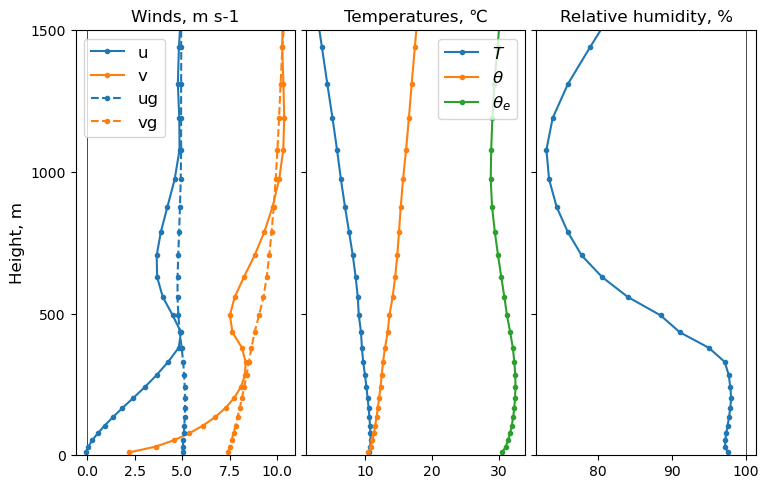

In [5]:
# Plot initial profiles in the lower atmosphere

# Restrict the dataset to the initial time and the lower atmosphere
ds0 = dsin.isel(time=0, nlev=slice(IZ0, None))
# Define which variables will be plotted
vbls = [
    [
        (ds0.u, dict(label='u', color='C0')), (ds0.v, dict(label='v', color='C1')),
        (ds0.ug, dict(label='ug', color='C0', linestyle='--')),
        (ds0.vg, dict(label='vg', color='C1', linestyle='--'))],
    [
        (ds0.t-TCELS, '$T$'), (ds0.pot_temperature-TCELS, '$\\theta$'),
        (ds0.pot_temp_e-TCELS, '$\\theta_e$')],
    ds0.relative_humidity*1e2
]
ncols = len(vbls)

axlineargs = dict(color='k', linewidth=.5)
lineargs = dict(marker='.')

# Set up the figure
fig, axs = plt.subplots(ncols=ncols, sharey=True, figsize=(8, 5))
fig.subplots_adjust(left=.1, bottom=.05, right=.95, top=.9, wspace=.05)
axs[0].set_ylabel(ZLABEL, fontsize=12)
axs[0].set_ylim(ZLIM)
axs[0].set_yticks(ZTICKS)
lines = [list() for icol in range(ncols)]
legs = [None for icol in range(ncols)]

# First plot: Winds
ax = axs[0]
ax.set_title('Winds, m s-1', fontsize=12)
ax.axvline(0, **axlineargs)
labels = list()
for (vbl, kwargs) in vbls[0]:
    labels.append(kwargs.pop('label'))
    lines[0] += ax.plot(vbl, ZM0, **kwargs, **lineargs)
legs[0] = ax.legend(lines[0], labels, fontsize=12)

# Second plot: Temperatures
ax = axs[1]
ax.set_title(f'Temperatures, {DEGC}', fontsize=12)
labels = list()
for (vbl, label) in vbls[1]:
    labels.append(label)
    lines[1] += ax.plot(vbl, ZM0, **lineargs)
legs[1] = ax.legend(lines[1], labels, fontsize=12)

# Third plot: Relative humidity
ax = axs[2]
ax.set_title('Relative humidity, %', fontsize=12)
ax.axvline(100, **axlineargs)
lines[2] += ax.plot(vbls[2], ZM0, **lineargs)
plt.show()

The geostrophic winds are southwesterly and fairly constant in height. (The slight shear in the meridional wind implies an eastward temperature gradient through thermal wind balance.) The actual winds are very close to geostrophic above 1 km; a little sub-geostrophic between 500 m and 1 km; and quite ageostrophic below 500 m.

The temperature gradient is actually positive near the surface - stable conditions. (This is 1 a.m. in October.) The potential temperature gradient is strictly positive so the atmosphere is statically stable. The equivalent potential temperature, however, increases near the surface and then decreases. The atmosphere is conditionally stable; enough lift from the surface could trigger convection.

The last panel shows that the relative humidity is nearly 100% up to about 400 m, after which it drops by about 20%. (This is reflected in the equivalent potential temperature.) Since the air is unsaturated, there are no significant low-level clouds. There are cloud remnants - up to 12% cloud cover in some layers - but these clouds will dissipate.

In [6]:
# Show the cloud coverage in % in the lower atmosphere
dsin.cloud_fraction.isel(time=0, nlev=slice(IZ0, None))*100

<xarray.DataArray 'cloud_fraction' (nlev: 25)> Size: 200B
array([ 0.     ,  0.     ,  0.78125,  0.78125,  1.5625 ,  1.5625 ,
        1.5625 ,  1.5625 ,  0.78125,  0.     ,  0.     ,  1.5625 ,
        1.5625 ,  6.25   , 11.71875,  6.25   ,  0.     ,  0.     ,
        0.     ,  0.     ,  0.     ,  0.     ,  0.     ,  0.     ,
        0.     ])
Coordinates:
  * nlev     (nlev) int32 100B 113 114 115 116 117 118 ... 133 134 135 136 137
    time     int64 8B 0

## Near-surface variables

Before moving on to the complicated plots let's first look at the evolution of the variables closest to the surface.

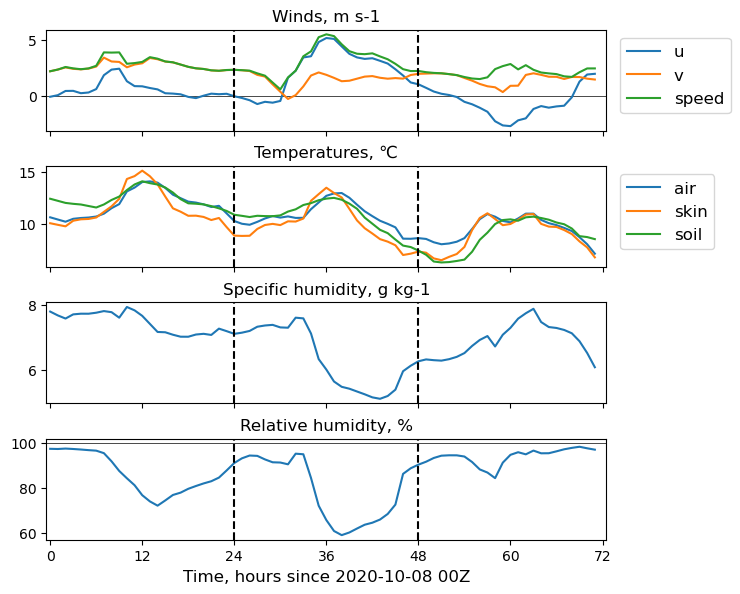

In [7]:
# Plot near-surface variables

# Restrict to the lowest level
ds0 = dsin.isel(nlev=-1, nlevp1=-1, nlevs=0)

# Define which variables to plot
vbls = [
    [(ds0.u, 'u'), (ds0.v, 'v'), ((ds0.u**2 + ds0.v**2)**.5, 'speed')],
    [(ds0.t, 'air'), (ds0.t_skin, 'skin'), (ds0.t_soil, 'soil')],
    ds0.q*1e3,
    ds0.relative_humidity*1e2
]
nrows = len(vbls)

axlineargs = dict(color='k', linewidth=.5)
legkwargs = dict(fontsize=12, loc='upper left', bbox_to_anchor=(1.01, 1))

# Set up a figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, figsize=(8, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.8, top=.95, hspace=.35)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xlim(TLIM)
axs[-1].set_xticks(TTICKS)
lines = [list() for _ in range(nrows)]
legs = [None for _ in range(nrows)]

# First variables: Winds
ax = axs[0]
ax.set_title('Winds, m s-1', fontsize=12)
ax.axhline(0, **axlineargs)
labels = list()
for (vbl, label) in vbls[0]:
    labels.append(label)
    lines[0] += ax.plot(TMID, vbl)
legs[0] = ax.legend(lines[0], labels, **legkwargs)

# Second variables: Temperatures
ax = axs[1]
ax.set_title(f'Temperatures, {DEGC}', fontsize=12)
labels = list()
for (vbl, label) in vbls[1]:
    labels.append(label)
    lines[1] += ax.plot(TMID, vbl-TCELS)
legs[1] = ax.legend(lines[1], labels, **legkwargs)

# Third and fourth variables: Humidities
ax = axs[2]
ax.set_title('Specific humidity, g kg-1', fontsize=12)
lines[2] += ax.plot(TMID, vbls[2])

ax = axs[3]
ax.set_title('Relative humidity, %', fontsize=12)
ax.axhline(100, **axlineargs)
lines[3] += ax.plot(TMID, vbls[3])

[[ax.axvline(x,c='k',ls="--") for x in [24,48]] for ax in axs]
plt.show()

The near-surface winds start out as southerly, changing suddenly to mostly westerly around hour 30 at which point the wind speed kicks up. As will become more apparent later, this marks a front passing through. This is followed by a slow turning of the wind, from southwesterly to southerly to southeasterly.

The temperatures show a diurnal cycle along with a gradual decline. The skin temperature has the greatest changes and the soil temperature the least (generally speaking). The soil and air temperature are usually fairly close, but it is the air-skin temperature difference that determines the sensible heat flux. Most of the time the skin temperature is lower, indicating a heat flux *into* the surface.
Remember what the skin temeprature represents: it is defined by the requirement that the net energy flux at the surface boundary interface must sum to zero at every instant:
$$
R_{net} - H - L_e - G = 0,
$$
where $R_{net}$ is the net radiation into the surface, $H$ is the sensible heat flux (heat flux _into the atmosphere_ due to temperature difference between surface and air), $L_e$ is the latent heat flux (heat flux _into the atmosphere_ due to phase changes in water), and $G$ is the conductive ground heat flux (usually quite small). It can also be seen (especially when dealing with satellites measuring the longwave radiation $LW$ or radiation schemes) as the temperature satifying the Stefan-Boltzmann equation, $LW = \epsilon \sigma T^4_{skin}$. 
In general, $T_{skin}$ can be seen as a measure of the thermal disequilibrium of the atmosphere. In the usual parametrisation for the surface heat flux used in Numerical Weather Prediction models, 
$$
H = \rho c_p C_H U_{z1}(T_{air}-T_{skin}),
$$
the difference between $T_{air}$ and $T_{skin}$ immediately indicates the cooling or heating of the layer (the other quantities are positive, with $U_{z1}$ being the velocity at the lowest level, $cp$ the specific heat capacity of air and $C_H$ the bulk heat-transfer coefficient).

The relative humidity also shows what looks like a diurnal cycle. The specific humidity, however, is relatively constant over the first 36 hours; the drop in relative humidity is only because of the increase in temperature. Without this context, it would be hard to tell that the second dip in relative humidity was not simply another diurnal cycle. The sudden drying out is another indicator of the frontal system.

## Whole-atmosphere variables

The most difficult components to plot are the prognostic variables like `u, v, t, q`. The most direct way to plot them is as 2D heat maps as follows.

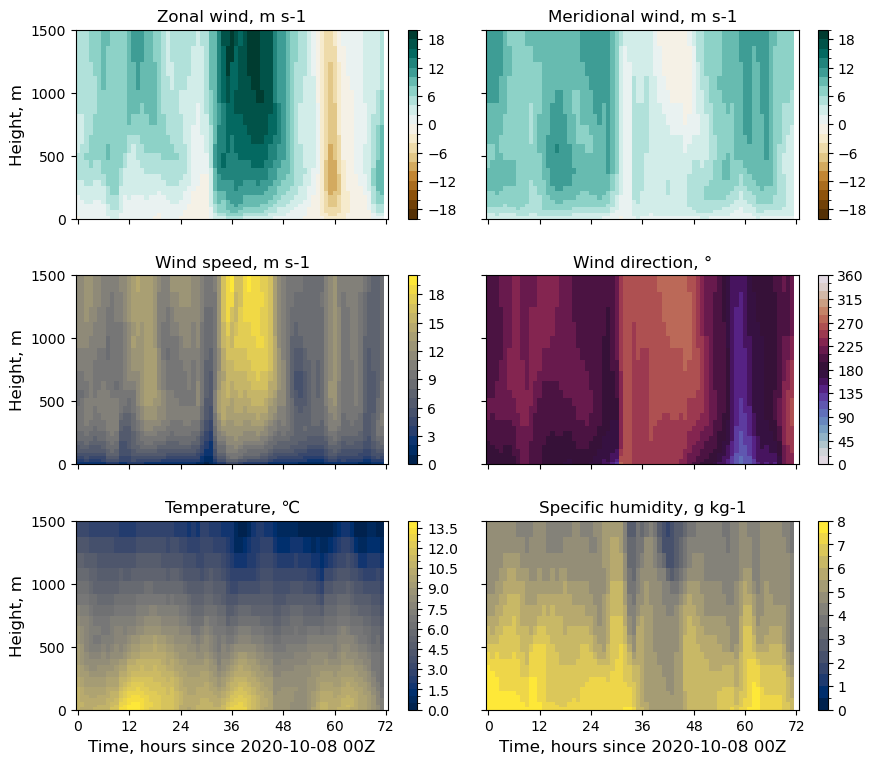

In [8]:
# Plot primary prognostic variables

# Define which variables to plot
# Now I include explicit boundaries for the color scale and a specific colormap
# I recommend BrBG for diverging data (equal positive and negative values);
# twilight for cyclic data (data wraps around, like angles);
# and cividis for sequential data (most other data)

# Arrange the variables to plot
ds0 = dsin.isel(nlev=slice(IZ0, None))
vbls = [
    (ds0.u, 'Zonal wind, m s-1', np.arange(-20, 20.1, 2), mpl.cm.BrBG),
    (ds0.v, 'Meridional wind, m s-1', np.arange(-20, 20.1, 2), mpl.cm.BrBG),
    ((ds0.u**2 + ds0.v**2)**.5, 'Wind speed, m s-1', np.arange(0, 20.1, 1), mpl.cm.cividis),
    (np.mod(270 - np.rad2deg(np.arctan2(ds0.v, ds0.u)), 360),
     f'Wind direction, {DEG}', np.arange(0, 361, 15), mpl.cm.twilight),
    (ds0.t-TCELS, f'Temperature, {DEGC}', np.arange(0, 14.1, .5), mpl.cm.cividis),
    (ds0.q*1e3, 'Specific humidity, g kg-1', np.arange(0, 8.1, .5), mpl.cm.cividis)
]
nplt = len(vbls)
ncols = 2
nrows = (nplt+1)//ncols

# Set up the figure
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, sharex=True, sharey=True, figsize=(9, 8))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3, wspace=.05)
for icol in range(ncols):
    axs[-1, icol].set_xlabel(TLABEL, fontsize=12)
    axs[-1, icol].set_xlim(TLIM)
    axs[-1, icol].set_xticks(TTICKS)
for irow in range(nrows):
    axs[irow, 0].set_ylabel(ZLABEL, fontsize=12)
    axs[irow, 0].set_ylim(ZLIM)
    axs[irow, 0].set_yticks(ZTICKS)

# Plot each element
ims, cbs = [np.empty_like(axs) for __ in range(2)]
for (iplt, (vbl, title, cbnds, cmap)) in enumerate(vbls):
    irow, icol = divmod(iplt, ncols)
    ax = axs[irow, icol]
    ax.set_title(title, fontsize=12)
    norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)
    im = ax.pcolormesh(TEDGE, ZEBAR, vbl.T, cmap=cmap, norm=norm)
    ims[irow, icol] = im
    cbs[irow, icol] = fig.colorbar(im, ax=ax)
plt.show()

There was definitely a shift around hour 32 (06:00 local on 10/09) that came with strong winds bringing dry air. The wind direction shifts from 180 degrees (southerly) to 270 degrees (westerly).

The absolute temperature isn't always easy to interpret: that's why we usually work with the potential temperature when dealing with the ABL:
$$
\theta = T \left( \frac{P_0}{P} \right)^{R_d/c_p}. 
$$
The potential temperature gives a better concept of the stability, since it eliminates the natural temperature decrease due to height (pressure-induced expansion) by referencing all air parcels to a constant pressure $P_0$ ($\theta$ is conserved in an adiabatic transformation). 

The "normal" temperature gradients might be misleading because air temperature bascially always decreases with height due to pressude-induced expansion, but an atmosphere with a negative temperature gradient can still be statically stable as long as T decreases at a rate slower than the (dry, in this case) adiabatic lapse rate $\Gamma_d$. \
​
This is also why the buoyancy term in the Navier-Stokes equation under Boussinesq approximation has $\theta$ and not $T$:
$$
\frac{Dw}{Dt} = \frac{g}{\theta_0}\cdot\theta + \dots
$$

The _equivalent_ potential temperature $\theta_e$ is basically the same thing but also takes into account the effect of moisture (it is the "temperature an air parcel would have if all its moisture was condensed - releasing heat - _and_ then brought adiabatically to $P_0$").


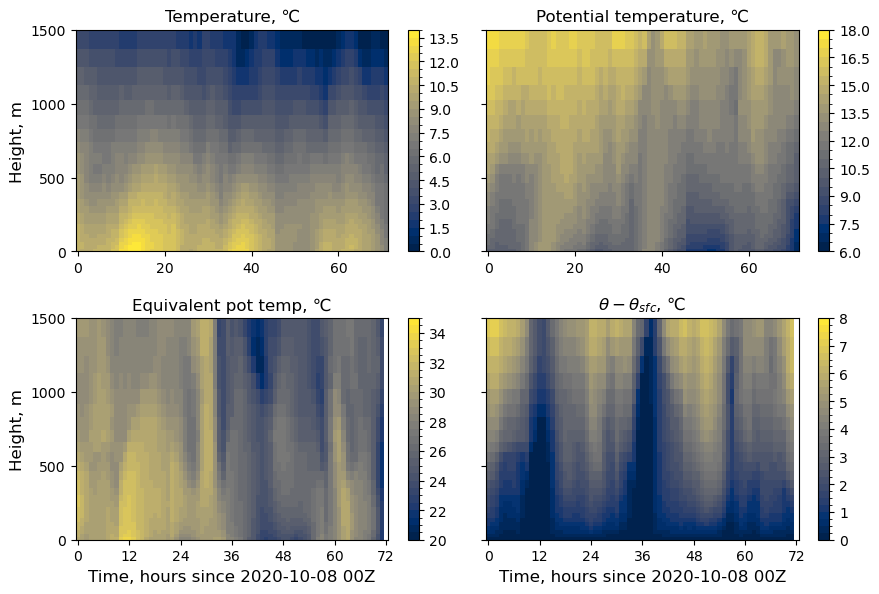

In [9]:
# Plot different temperature fields

# Define which variables to plot
ds0 = dsin.isel(nlev=slice(IZ0, None))
vbls = [
    (ds0.t-TCELS, f'Temperature, {DEGC}', np.arange(0, 14.1, .5)),
    (ds0.pot_temperature-TCELS, f'Potential temperature, {DEGC}', np.arange(6, 18.1, .5)),
    (ds0.pot_temp_e-TCELS, f'Equivalent pot temp, {DEGC}', np.arange(20, 35.1, .5)),
    (ds0.pot_temperature - ds0.pot_temperature.isel(nlev=-1),
     f'$\\theta - \\theta_{{sfc}}$, {DEGC}', np.arange(0, 8.1, .25))
]
nplt = len(vbls)
ncols = 2
nrows = (nplt+1)//ncols
cmap = mpl.cm.cividis

# Set up the figure
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, sharey=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3, wspace=.05)
for icol in range(ncols):
    axs[-1, icol].set_xlabel(TLABEL, fontsize=12)
    axs[-1, icol].set_xlim(TLIM)
    axs[-1, icol].set_xticks(TTICKS)
for irow in range(nrows):
    axs[irow, 0].set_ylabel(ZLABEL, fontsize=12)
    axs[irow, 0].set_ylim(ZLIM)
    axs[irow, 0].set_yticks(ZTICKS)

# Plot each element
ims, cbs = [np.empty_like(axs) for __ in range(2)]
for (iplt, (vbl, title, cbnds)) in enumerate(vbls):
    irow, icol = divmod(iplt, ncols)
    ax = axs[irow, icol]
    ax.set_title(title, fontsize=12)
    norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)
    im = ax.pcolormesh(TEDGE, ZEBAR, vbl.T, cmap=cmap, norm=norm)
    ims[irow, icol] = im
    cbs[irow, icol] = fig.colorbar(im, ax=ax)
plt.show()

The potential temperature difference $\theta - \theta_{sfc}$ shows the boundary layer height: its value should be nearly zero throughout the (daytime) boundary layer. It has a diurnal cycle, slowly growing to a maximum of 1-1.5 km before collapsing back down around sunset.

The temperature and potential temperature don't show the frontal passage very well but the equivalent potential temperature does. The equivalent potential temperature is so much lower after the frontal passage because the air is so much _dryer_.

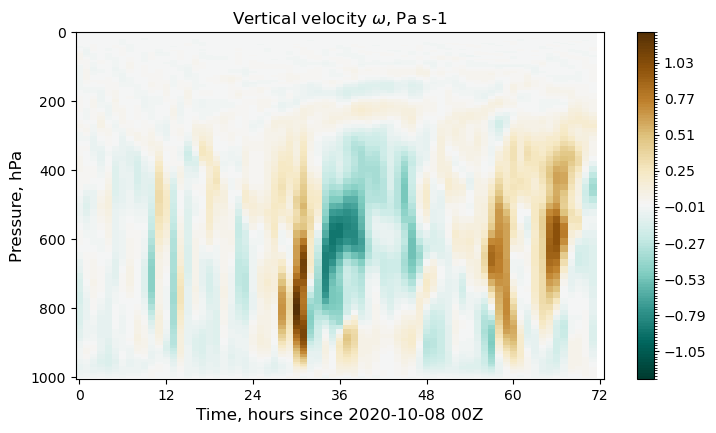

In [10]:
# Plot the vertical velocity (omega) field over the whole atmosphere

# Set up variables to plot
y = dsin.pressure_h.isel(time=0)*1e-2  # Convert Pa to hPa
yticks = np.arange(1e3, -.1, -200)
cbnds = np.arange(-1.25, 1.251, .02)
cmap = mpl.cm.BrBG_r
norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)

# Set up a figure and plot
fig, ax = plt.subplots(figsize=(8, 4.5))
fig.subplots_adjust(right=.95)
ax.set_xlabel(TLABEL, fontsize=12)
ax.set_xlim(TLIM)
ax.set_xticks(TTICKS)
ax.set_ylabel(PLABEL, fontsize=12)
ax.set_yticks(yticks)
ax.set_ylim(PLIM[0], 0)
ax.set_title(r'Vertical velocity $\omega$, Pa s-1', fontsize=12)
im = ax.pcolormesh(TEDGE, y, -dsin.omega.T, cmap=cmap, norm=norm)
cb = fig.colorbar(im, ax=ax)
plt.show()

Negative values of $\omega$ in light blue represent subsidence and adiabatic heating; positive values of $\omega$ in brown represent lifting and adiabatic cooling. The shift that happens around hour 36 is preceded by a strong lifting event followed by strong subsidence.



You may sometimes need to plot fields where a value of zero has an extra meaning. When plotting the cloud ice water, for example, a value of zero could mean "no cloud" but it could also mean "cloud with only liquid water". In these cases, you can mask the variables using the `.where(cond)` function of `xarray` objects. This function returns an array or dataset where all locations where the condition `cond` is **not** met are NaNs. Most plotting utilities like `pyplot.pcolormesh` will not color in NaN values, which can make it much clearer when there is or is not a cloud.

You can detect the presence of a cloud via e.g. `dsin.ql.where(dsin.cloud_fraction > 0)`. There are a couple of caveats to this:
- This version of IFS has a habit of "diffusing" clouds too much, leading to grid cells with very low cloud fractions rather than a well-defined cloud base. You might need to choose a minimum cloud fraction rather than just look for `cloud_fraction=0`.
- There can be occurrences of small amounts of cloud liquid/ice water where `cloud_fraction=0` and nonzero cloud fraction where `ql+qi=0`. Whichever variable you choose to mask with, there can always be some discrepancy with the other approach. I use `cloud_fraction` because I often divide other variables by cloud fraction when analyzing them.

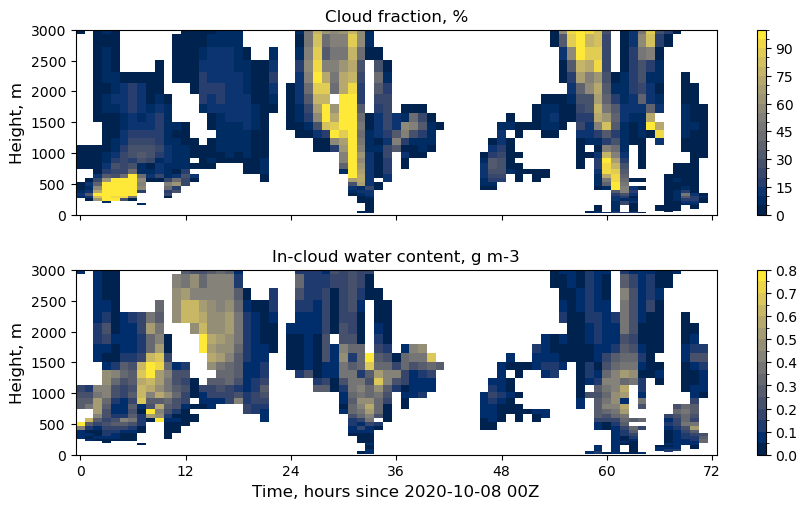

In [11]:
# Plot cloud fraction and cloud water content

# Choose a minimum value of cloud fraction
CFMIN = 1  # Mask cloud fractions >1%
# Extend the plot a little higher, up to 3 km
zmax = 3e3
iz0 = np.nonzero(dsin.height_h.mean(dim='time').data >= zmax)[0][-1] - 1
zebar = dsin.height_h.mean(dim='time').data[iz0:]
zlim = (0, zmax)
zticks = np.arange(0, zmax+1, 500)
# Set up the conditional to mask with
ds0 = dsin.isel(nlev=slice(iz0, None))
hascld = (ds0.cloud_fraction*1e2 > CFMIN)

# Set up the variables to plot
cldfrac = ds0.cloud_fraction.where(hascld)
rho = ds0.pressure_f/(287.05967*ds0.t)  # Calculate density
cwc = (ds0.ql + ds0.qi).where(hascld)/cldfrac*rho  # Cloud water content
vbls = [
    (cldfrac*1e2, 'Cloud fraction, %', np.arange(0, 101, 5)),
    (cwc*1e3, 'In-cloud water content, g m-3', np.arange(0, 0.81, .05))
]
nrows = len(vbls)
cmap = mpl.cm.cividis

# Set up the figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, sharey=True, figsize=(9, 5))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3, wspace=.05)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xlim(TLIM)
axs[-1].set_xticks(TTICKS)
for irow in range(nrows):
    axs[irow].set_ylabel(ZLABEL, fontsize=12)
    axs[irow].set_ylim(zlim)
    axs[irow].set_yticks(zticks)

# Plot each variable
ims, cbs = [np.empty_like(axs) for __ in range(2)]
for (irow, (vbl, title, cbnds)) in enumerate(vbls):
    norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)
    ax = axs[irow]
    ax.set_title(title, fontsize=12)
    im = ax.pcolormesh(TEDGE, zebar, vbl.T, norm=norm, cmap=cmap)
    ims[irow] = im
    cbs[irow] = fig.colorbar(im, ax=ax)
plt.show()

The case starts off with some low clouds that lift and burn off throughout the first day. Clouds develop again the following night, getting fairly low and thick before the frontal passage. Afterwards they lift again. The third day has some development of low clouds, but nothing very persistent.

# Advection terms

Advection terms are forcings in the single-column model:
$$ \frac{\partial T}{\partial t} = -\mathbf{u} \cdot \nabla T + \ldots $$
for temperature and similarly for humidity $q$ and momentum $u, v$.

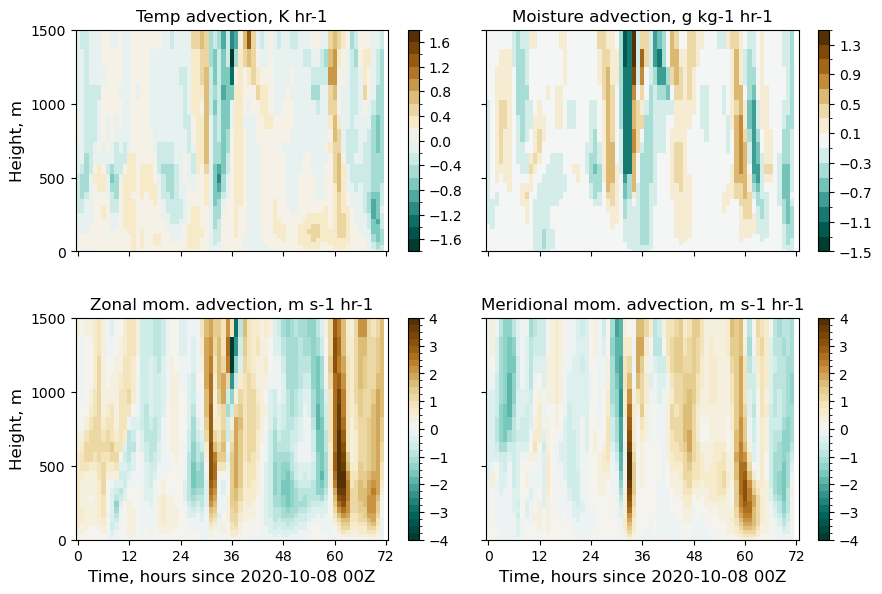

In [12]:
# Plot advection terms

# Define the variables to plot
ds0 = dsin.isel(nlev=slice(IZ0, None))
cmap = mpl.cm.BrBG_r
vbls = [
    (ds0.tadv*3600, 'Temp advection, K hr-1', np.arange(-1.8, 1.81, .2)),
    (ds0.qadv*1e3*3600, 'Moisture advection, g kg-1 hr-1', np.arange(-1.5, 1.51, .2)),
    (ds0.uadv*3600, 'Zonal mom. advection, m s-1 hr-1', np.arange(-4, 4.1, .25)),
    (ds0.vadv*3600, 'Meridional mom. advection, m s-1 hr-1', np.arange(-4, 4.1, .25))
]
nplt = len(vbls)
ncols = 2
nrows = (nplt+1)//ncols

# Set up the figure
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, sharex=True, sharey=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3, wspace=.05)
for icol in range(ncols):
    axs[-1, icol].set_xlabel(TLABEL, fontsize=12)
    axs[-1, icol].set_xlim(TLIM)
    axs[-1, icol].set_xticks(TTICKS)
for irow in range(nrows):
    axs[irow, 0].set_ylabel(ZLABEL, fontsize=12)
    axs[irow, 0].set_ylim(ZLIM)
    axs[irow, 0].set_yticks(ZTICKS)

# Plot each element
ims, cbs = [np.empty_like(axs) for __ in range(2)]
for (iplt, (vbl, title, cbnds)) in enumerate(vbls):
    irow, icol = divmod(iplt, ncols)
    ax = axs[irow, icol]
    ax.set_title(title, fontsize=12)
    norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)
    im = ax.pcolormesh(TEDGE, ZEBAR, vbl.T, cmap=cmap, norm=norm)
    ims[irow, icol] = im
    cbs[irow, icol] = fig.colorbar(im, ax=ax)
plt.show()

What we can see is that there is typically heat advected into the column near the surface (lowest ~250 m) with fairly weak advection out of the column above. The mean humidity advection field is almost always close to zero except around the frontal passage.

The momentum advection is evident around the frontal passage, but also in the middle of the third day. This could be another front - it shows up in the temperature and humidity fields as well - but it seems weaker.

# MY OWN STUFF